# M02-2 | Insert Observers and Fake Quant into the Graph by Hand, Without a Quantizer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m02_observer_fakequant/02_manual_insert.ipynb)

M01 showed `prepare_pt2e` inserting observers into the graph. The Quantizer decides the positions (the topic of M03); take "deciding the positions" away and what remains is graph editing:

1. Build an observer module and attach it to the GraphModule with `gm.add_submodule(name, module)`.
2. Insert a `call_module` node in the graph, and make the consumers that used to read from the upstream read from it instead.

These two steps are Steps 1 to 3 of M00-4 (insert, rewire, recompile). If they are unfamiliar, run [M00-4](../m00_export_basics/04_fx_graph_editing.ipynb) once first.

- **A.** Insert observers by hand at three positions in conv → relu, calibrate, and compare the qparams one by one against `prepare_pt2e`.
- **B.** Replace the observers with `FakeQuantize`: same positions, but forward now really does quantize → dequantize.
- **C.** The two switches of `FakeQuantize`: `observer_enabled` and `fake_quant_enabled`.

The model is `ConvReLU` without BN, to avoid `prepare_pt2e` folding BN and making the graphs differ (M04).

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m02_observer_fakequant")

In [2]:
import copy

import torch

from common.graph_utils import observer_nodes, sqnr
from common.models import example_inputs, get_model
from common.pt2e import (
    FakeQuantize,
    MinMaxObserver,
    PerChannelMinMaxObserver,
    disable_fake_quant,
    disable_observer,
    enable_fake_quant,
    enable_observer,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. Insert Observers by Hand and Compare with `prepare_pt2e`

The core insertion takes only three lines: attach the module, create a `call_module` after `node`, and rewire the users of `node` to the new node (except the new node itself).

In [3]:
def insert_after(gm, node, module, name):
    """Insert call_module(name) after node; users that consumed node now consume the new node."""
    gm.add_submodule(name, module)                       # 1. attach the module so call_module can find it
    with gm.graph.inserting_after(node):
        new = gm.graph.call_module(name, (node,))        # 2a. new node: name(node)
    node.replace_all_uses_with(new, delete_user_cb=lambda user: user is not new)  # 2b. rewire the downstream
    return new

Where to insert, and which kind of observer? To allow a one-by-one comparison with `prepare_pt2e`, both follow the XNNPACKQuantizer configuration:

- **Positions**: the input `x`, the conv weight, and the relu output (in the M01 overview example, `prepare_pt2e` also inserts at these three places).
- **Observer kind and parameters**: built directly from the `QuantizationSpec` in the quantizer configuration, not hard-coded here. This is also what `prepare_pt2e` does for each annotation.

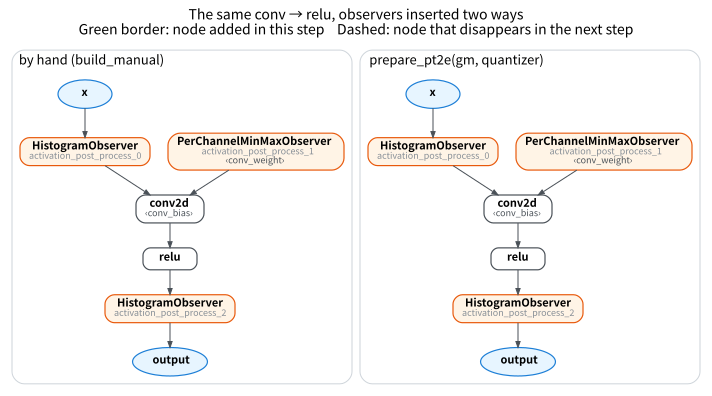

In [4]:
def observer_from_spec(spec):
    """Build an observer from a QuantizationSpec."""
    kwargs = dict(dtype=spec.dtype, qscheme=spec.qscheme, quant_min=spec.quant_min,
                  quant_max=spec.quant_max, is_dynamic=spec.is_dynamic)
    if spec.ch_axis is not None:
        kwargs["ch_axis"] = spec.ch_axis
    return spec.observer_or_fake_quant_ctr.with_args(**kwargs)()


def build_manual(gm, make_act, make_weight):
    """Insert at x, conv weight, and relu output, named following the prepare_pt2e convention."""
    by_name = {n.name: n for n in gm.graph.nodes}
    insert_after(gm, by_name["x"], make_act(), "activation_post_process_0")
    insert_after(gm, by_name["conv_weight"], make_weight(), "activation_post_process_1")
    insert_after(gm, by_name["relu"], make_act(), "activation_post_process_2")
    gm.recompile()  # always recompile after editing the graph so forward is updated
    return gm


model = get_model("conv_relu").eval()
gm = export_module(model, example_inputs(4))
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
cfg = quantizer.global_config
assert cfg is not None and cfg.input_activation is not None and cfg.weight is not None
act_spec, weight_spec = cfg.input_activation, cfg.weight

manual = build_manual(copy.deepcopy(gm), lambda: observer_from_spec(act_spec), lambda: observer_from_spec(weight_spec))
auto = prepare_pt2e(copy.deepcopy(gm), quantizer)
draw_stages([(manual, "by hand (build_manual)"), (auto, "prepare_pt2e(gm, quantizer)")],
            title="The same conv → relu, observers inserted two ways")

The observer positions and kinds in the two graphs are the same (the second has no green boxes because, compared with the first, no node was added or removed).
Now feed both the same calibration data and compare the computed scale and zero point one by one:

In [5]:
def calibrate(gm, n=8, seed=0):
    g = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        for _ in range(n):
            gm(torch.randn(4, 3, 16, 16, generator=g))


calibrate(manual)
calibrate(auto)
rows, same = [], []
for (nm, om), (na, oa) in zip(observer_nodes(manual), observer_nodes(auto)):
    sm, zm = om.calculate_qparams()
    sa, za = oa.calculate_qparams()
    same.append(nm.name == na.name and torch.equal(sm, sa) and torch.equal(zm, za))
    rows.append([nm.name, nm.args[0].name, type(om).__name__, sm.numel(), "identical" if same[-1] else "different"])
table(rows, ["observer", "observed node", "kind", "# of scales", "vs. prepare_pt2e"])

observer,observed node,kind,# of scales,vs. prepare_pt2e
activation_post_process_1,conv_weight,PerChannelMinMaxObserver,8,identical
activation_post_process_0,x,HistogramObserver,1,identical
activation_post_process_2,relu,HistogramObserver,1,identical


In [6]:
assert len(rows) == len(observer_nodes(auto)) == 3 and all(same)

`prepare_pt2e` has no magic: for this model, all it does is attach observers at three positions. The only difference is that it decides the positions from the Quantizer's annotations, whereas we specified them manually.

## B. Replace the Observers with `FakeQuantize`

`FakeQuantize` is the module used by QAT. Its forward (torchao `fake_quantize.py`) does two things:

1. If `observer_enabled`: use the inner observer to record the range, and update scale and zero point.
2. If `fake_quant_enabled`: use the current scale and zero point to do quantize → dequantize, outputting **floats** that carry quantization error.

In other words, observers only peek; fake quant lets later layers see the quantization error, so QAT can learn to tolerate it (M06).
The "Adding the observer" section of the blog post <[Understanding Fake Quantization in Quantization Aware Training](https://bobondemon.github.io/2022/11/19/%E6%90%9E%E6%87%82-Quantization-Aware-Training-%E4%B8%AD%E7%9A%84-Fake-Quantization/#%E5%8A%A0%E5%85%A5-observer)> (in Chinese) explains the same thing with code; the import paths there are from the `torch.ao` era, and for torchao's names see `common/pt2e.py`.
Use the same `build_manual` at the same three positions, only with the module swapped for `FakeQuantize`:

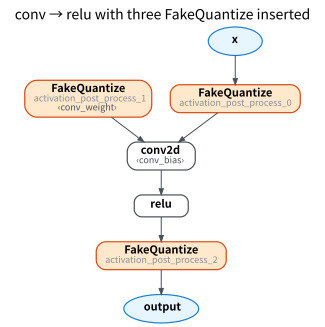

In [7]:
EPS = 2**-12  # same eps as XNNPACKQuantizer


def fq_act():
    return FakeQuantize(observer=MinMaxObserver, dtype=torch.int8, qscheme=torch.per_tensor_affine,
                        quant_min=-128, quant_max=127, eps=EPS)


def fq_weight():
    return FakeQuantize(observer=PerChannelMinMaxObserver, ch_axis=0, dtype=torch.int8,
                        qscheme=torch.per_channel_symmetric, quant_min=-127, quant_max=127, eps=EPS)


fq_model = build_manual(copy.deepcopy(gm), fq_act, fq_weight)
draw(fq_model, title="conv → relu with three FakeQuantize inserted")

Feed the same input to the fp32 model, the observer version (`manual` from part A), and the fake quant version:

In [8]:
x = torch.randn(4, 3, 16, 16)
with torch.no_grad():
    y_fp32, y_obs, y_fq = model(x), manual(x), fq_model(x)
obs_same, fq_same = torch.equal(y_obs, y_fp32), torch.equal(y_fq, y_fp32)
table([["observer version", obs_same, "—"], ["FakeQuantize version", fq_same, f"{sqnr(y_fp32, y_fq):.1f}"]],
      ["model", "output == fp32?", "SQNR vs. fp32 (dB)"])

model,output == fp32?,SQNR vs. fp32 (dB)
observer version,True,—
FakeQuantize version,False,40.2


In [9]:
assert obs_same and not fq_same

The observer version's output is bit-for-bit identical to fp32, while the fake quant version carries quantization error.

## C. The Two Switches of `FakeQuantize`

The two switches are buffers on the module, flipped for the whole graph at once with functions like `model.apply(disable_observer)`.
Do three things in order and watch the scale of the fake quant on the input `x` (`activation_post_process_0`):

1. With both on, feed a batch with a much larger range.
2. After `disable_observer`, feed data with an even larger range.
3. Then `disable_fake_quant`, and check whether the output returns to fp32.

In [10]:
fq_mod = fq_model.get_submodule("activation_post_process_0")
assert isinstance(fq_mod, FakeQuantize)


def state():
    flags = {name: getattr(fq_mod, f"{name}_enabled") for name in ("observer", "fake_quant")}  # the two switches are buffers
    return " ".join(f"{name}={int(t[0])}" for name, t in flags.items() if isinstance(t, torch.Tensor))


big = torch.randn(4, 3, 16, 16) * 5
scales = [float(fq_mod.scale)]
with torch.no_grad():
    fq_model(big)
    scales.append(float(fq_mod.scale))
    rows = [[state(), "feed data 5x in magnitude", f"{scales[0]:.5f} → {scales[1]:.5f}"]]

    fq_model.apply(disable_observer)
    fq_model(big * 10)
    scales.append(float(fq_mod.scale))
    rows.append([state(), "feed data 50x in magnitude", f"{scales[1]:.5f} → {scales[2]:.5f}"])

    fq_model.apply(disable_fake_quant)
    back_to_fp32 = torch.equal(fq_model(x), y_fp32)
    rows.append([state(), "output == fp32?", str(back_to_fp32)])
table(rows, ["switch state", "what was done", "scale / result"])

switch state,what was done,scale / result
observer=1 fake_quant=1,feed data 5x in magnitude,0.02829 → 0.15217
observer=0 fake_quant=1,feed data 50x in magnitude,0.15217 → 0.15217
observer=0 fake_quant=0,output == fp32?,True


In [11]:
assert scales[1] > scales[0] and scales[2] == scales[1] and back_to_fp32
_ = fq_model.apply(enable_fake_quant)  # restore both on
_ = fq_model.apply(enable_observer)

- **observer on**: the scale grows with the new data.
- **`disable_observer`**: the scale freezes; no amount of larger data changes it, but quantize → dequantize still happens.
- **`disable_fake_quant`**: no quantize → dequantize, and the output returns to fp32.

QAT (M06) flips these two switches at different times, for example keeping fake quant but turning off the observer before evaluation (M06-2).

## Summary

- `prepare_pt2e` inserting observers = `add_submodule` + `call_module` + `replace_all_uses_with`, and the hand-made result matches it item by item.
- The observer kind and parameters come from the `QuantizationSpec`'s `observer_or_fake_quant_ctr`.
- `FakeQuantize` = observer + quantize → dequantize; each of the two has its own switch.
- Next: M02-3 replaces the calibrated observers with quantize/dequantize nodes, i.e., does `convert_pt2e` by hand.